# Phase 1 – Cycle-Time Study of a 4-Robot Assembly Cell
**Data:** Future Factories Platform V2, University of South Carolina – analog dataset, 8 h run on 13 Aug 2024
(Harik et al., arXiv:2502.05020, licence CC BY-SA 4.0).

**Goal of Phase 1**
1. Load and check the analog data.
2. Split the 8-hour run into individual cycles using the PLC cycle-state signal.
3. Build the **state-time table** (cycle × state, seconds).
4. Find out which robot works in which state (from joint motion – not documented in the dataset).
5. Identify where the cycle time goes, what varies, and what happened in the slow cycles.

In [49]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Folder with the analog files (R01_Data.xlsx ... Conveyor_Signals.csv)
DATA_DIR = r'E:\claude github projects\future-factories\data'
OUT_DIR  = r'E:\claude github projects\future-factories\outputs'
if os.path.exists('/kaggle/input'):            # running on Kaggle: data is attached under /kaggle/input
    DATA_DIR, OUT_DIR = '/kaggle/input', '/kaggle/working/phase1_output'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style
INK, INK2, GRID = '#191919', '#666666', '#e6e6e6'
COL = {'R01': '#257de0', 'R02': '#f47230', 'R02 + R03': '#00b894', 'R04': '#f2a600', 'No robot motion': '#bdbdbd'}
plt.rcParams.update({'figure.dpi': 110, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID, 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

## 1. Load data
The files are Excel workbooks (note: `Conveyor_Signals.csv` is actually an Excel file despite its extension). Reading them takes ~2 min, so a cached copy is saved after the first run.

In [50]:
FILES = {'R01': 'R01_Data', 'R02': 'R02_Data', 'R03': 'R03_Data', 'R04': 'R04_Data',
         'safety': 'FFCellSafetyManagement', 'cycle': 'FFCell_CycleManagement', 'conveyor': 'Conveyor_Signals'}

def load(key):
    cache = os.path.join(OUT_DIR, f'_cache_{key}.pkl')
    if os.path.exists(cache):
        return pd.read_pickle(cache)
    path = sorted(glob.glob(os.path.join(DATA_DIR, '**', f'*{FILES[key]}*'), recursive=True))[0]   # searches sub-folders too
    try:
        df = pd.read_excel(path, engine='openpyxl')
    except Exception:
        df = pd.read_csv(path)
    df['_time'] = pd.to_datetime(df['_time'], format='ISO8601')
    df.to_pickle(cache)
    return df

D = {k: load(k) for k in FILES}
for k, d in D.items():
    print(f'{k:9s} {d.shape[0]:>7,} rows  {d.shape[1]} cols')

R01       287,954 rows  9 cols
R02       287,954 rows  9 cols
R03       287,954 rows  9 cols
R04       287,954 rows  9 cols
safety    287,954 rows  4 cols
cycle     287,954 rows  5 cols
conveyor  287,954 rows  10 cols


## 2. Data checks

In [51]:
cyc = D['cycle']
# all files share the same timestamps?
print('Timestamps identical across files:', all(D[k]['_time'].equals(cyc['_time']) for k in FILES))
dt = cyc['_time'].diff().dt.total_seconds()
print(f"Recording: {cyc['_time'].min():%H:%M:%S} – {cyc['_time'].max():%H:%M:%S} UTC "
      f"({(cyc['_time'].max()-cyc['_time'].min()).total_seconds()/3600:.2f} h)")
print(f'Sampling interval: median {dt.median()*1000:.0f} ms, max gap {dt.max():.2f} s')
print('Cycle states present:', sorted(int(v) for v in cyc['Q_Cell_CycleState'].unique()))
print('Missing values:', {k: int(d.isna().sum().sum()) for k, d in D.items()})

Timestamps identical across files: True
Recording: 14:00:00 – 21:59:59 UTC (8.00 h)
Sampling interval: median 96 ms, max gap 1.85 s
Cycle states present: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Missing values: {'R01': 0, 'R02': 0, 'R03': 0, 'R04': 0, 'safety': 0, 'cycle': 418083, 'conveyor': 0}


**Notes**
- ~10 Hz sampling, no significant gaps → time per state can be summed from sample intervals.
- Missing values are only in `Description` (the defect-scenario label) and the empty `I_MHS_GreenRocketTray` column.
- State 0 appears for a fraction of a second twice (when the defect scenario was switched) – ignored.

## 3. Split the run into cycles
A new cycle starts every time the cell enters **state 1** (R01 picks up the tray). Time in each state = sum of sample intervals while in that state.

In [52]:
df = cyc[['_time', 'Q_Cell_CycleCount', 'Q_Cell_CycleState', 'Description']].copy()
st = df['Q_Cell_CycleState']
df['cycle'] = ((st == 1) & (st.shift() != 1)).cumsum()       # 0 = partial cycle before the first state-1 entry
df['dt'] = df['_time'].shift(-1).sub(df['_time']).dt.total_seconds().fillna(0)

cycles = df[df.cycle >= 1].groupby('cycle').agg(start=('_time', 'first'),
                                                scenario=('Description', lambda s: s.dropna().iloc[-1] if s.notna().any() else 'Normal'))
cycles['cycle_time_s'] = (cycles['start'].shift(-1) - cycles['start']).dt.total_seconds()
cycles['scenario'] = cycles['scenario'].str.replace(',', ', ')

# Last cycle: recording ends while the cell is still in state 21 -> cycle time unknown
complete = cycles['cycle_time_s'].notna()
print(f'Cycles found: {len(cycles)}  (complete with known cycle time: {complete.sum()})')
print('Partial segment before first cycle:', round(df.loc[df.cycle == 0, 'dt'].sum(), 1), 's (excluded)')
cycles['scenario'].value_counts()

Cycles found: 93  (complete with known cycle time: 92)
Partial segment before first cycle: 40.7 s (excluded)


scenario
Normal                      40
NoNose, NoBody2             18
NoNose, NoBody2, NoBody1    18
NoNose                      17
Name: count, dtype: int64

The `Description` field marks the **defect scenarios** – parts deliberately left out of the tray:
cycles 1–25 normal, then *NoNose*, *NoNose, NoBody2*, *NoNose, NoBody2, NoBody1*, and normal again from cycle 79.

## 4. State-time table (cycle × state, seconds)

In [53]:
STATES = list(range(1, 22))
stt = (df[df.cycle >= 1].pivot_table(index='cycle', columns='Q_Cell_CycleState', values='dt', aggfunc='sum')
       .reindex(columns=STATES).fillna(0))
stt.columns = [f'S{s:02d}' for s in STATES]
stt = stt[complete.values]                          # complete cycles only
stt['Total'] = stt.sum(axis=1)
stt.round(1).head(10)

,S01,S02,S03,S04,S05,S06,S07,S08,S09,S10,...,S13,S14,S15,S16,S17,S18,S19,S20,S21,Total
cycle,,,,,,,,,,,,,,,,,,,,,
1,8.2,7.4,1.6,12.5,5.1,5.2,5.3,68.2,87.1,11.2,...,7.2,8.5,10.0,10.5,8.2,7.9,5.4,6.9,1.0,296.6
2,8.7,7.4,1.6,12.5,5.3,5.0,5.3,69.0,86.6,11.0,...,7.3,8.6,10.0,10.2,8.4,7.9,5.5,6.8,1.0,297.3
3,8.8,7.4,1.8,12.3,5.1,5.2,5.2,68.4,86.0,11.1,...,7.7,8.2,10.1,10.2,8.4,8.0,5.4,6.9,1.0,296.3
4,8.8,7.4,1.6,12.5,5.1,5.2,5.3,68.2,85.3,11.0,...,7.3,8.5,10.1,10.2,8.5,8.0,5.3,6.8,1.1,295.4
5,8.8,7.6,1.5,12.4,5.0,5.3,5.3,68.1,85.2,10.9,...,7.3,8.5,10.1,10.2,8.4,8.0,5.4,6.9,1.0,295.0
6,8.8,7.5,1.5,12.5,5.1,5.2,5.1,68.4,85.9,11.1,...,7.3,8.5,10.1,10.1,8.4,8.0,5.4,7.2,0.9,296.1
7,8.6,7.4,1.6,12.5,5.2,5.1,5.1,68.4,86.5,11.0,...,7.3,8.5,10.1,10.2,8.6,7.8,5.4,6.8,1.1,296.4
8,8.9,7.4,1.5,12.7,5.0,5.2,5.1,68.4,85.6,11.1,...,7.3,8.6,10.0,10.3,8.4,7.9,5.4,6.8,1.1,295.8
9,8.7,7.4,1.6,12.5,5.1,5.2,5.2,68.3,86.1,11.0,...,7.4,8.4,10.1,10.2,8.4,8.0,5.4,6.8,1.0,296.0


In [54]:
# check: sum of state times = cycle time measured start-to-start
diff = (stt['Total'] - cycles.loc[stt.index, 'cycle_time_s']).abs().max()
print(f'Max difference between summed state times and start-to-start cycle time: {diff:.3f} s')

Max difference between summed state times and start-to-start cycle time: 0.099 s


## 5. Which robot works in which state?
The dataset does not document the 21 states. Joint-angle changes show which robot is moving in each state (moving = summed |Δangle| > 0.05° per sample).

In [55]:
motion = pd.DataFrame({r: D[r].filter(like='JointAngle').diff().abs().sum(axis=1) for r in ['R01','R02','R03','R04']})
motion['state'] = st.values
motion['cycle'] = df['cycle'].values
ref = motion[motion.cycle.between(1, 25)]           # normal, undisturbed cycles as reference
moving = ref[['R01','R02','R03','R04']] > 0.05
share = moving.groupby(ref['state']).mean().reindex(STATES)
share['any robot'] = moving.any(axis=1).groupby(ref['state']).mean().reindex(STATES)

def owner(row):
    act = [r for r in ['R01','R02','R03','R04'] if row[r] > 0.2]
    if row['any robot'] < 0.2: return 'No robot motion'
    if act == ['R02','R03'] or act == ['R03']: return 'R02 + R03'
    return act[0] if act else 'No robot motion'
share['active'] = share.apply(owner, axis=1)
share.index = [f'S{s:02d}' for s in STATES]
(share.style.format({c: '{:.0%}' for c in ['R01','R02','R03','R04','any robot']}))

,R01,R02,R03,R04,any robot,active
S01,81%,0%,0%,1%,82%,R01
S02,85%,0%,0%,0%,85%,R01
S03,83%,0%,0%,0%,83%,R01
S04,2%,35%,0%,0%,37%,R02
S05,0%,89%,0%,0%,89%,R02
S06,0%,88%,0%,0%,88%,R02
S07,0%,85%,0%,0%,85%,R02
S08,0%,28%,76%,0%,87%,R02 + R03
S09,0%,0%,0%,7%,7%,No robot motion
S10,0%,0%,0%,93%,93%,R04


**State map (derived from motion):**
- **S01–S03 → R01** – tray handling from the material handling station.
- **S04–S07 → R02** – picking/placing the body parts.
- **S08 → R02 + R03** – assembly (mostly R03 moving).
- **S09 → no robot motion** for ~93 % of the time – the tray is travelling/waiting on the conveyor between assembly and disassembly.
- **S10–S21 → R04** – disassembly and return of the parts.

Only one robot moves at a time (except S08): the cell runs **strictly sequentially**.

## 6. Cycle-time results

In [56]:
ct = cycles.loc[stt.index, 'cycle_time_s']
med = ct.median()
print(f'Complete cycles: {len(ct)}')
print(f'Cycle time  median {med:.1f} s | mean {ct.mean():.1f} s | std {ct.std():.1f} s | min {ct.min():.1f} s | max {ct.max():.1f} s')
slow = ct[ct > med * 1.05]
print(f'Cycles >5 % slower than median: {len(slow)} -> {list(slow.index)}')
lost = (slow - med).sum()
print(f'Time lost in these cycles vs median: {lost:.0f} s ({lost/60:.1f} min) = '
      f'{lost/med:.1f} cycles of output')

Complete cycles: 92
Cycle time  median 295.4 s | mean 306.6 s | std 41.3 s | min 293.8 s | max 522.3 s
Cycles >5 % slower than median: 10 -> [22, 34, 43, 72, 79, 81, 82, 83, 84, 85]
Time lost in these cycles vs median: 958 s (16.0 min) = 3.2 cycles of output


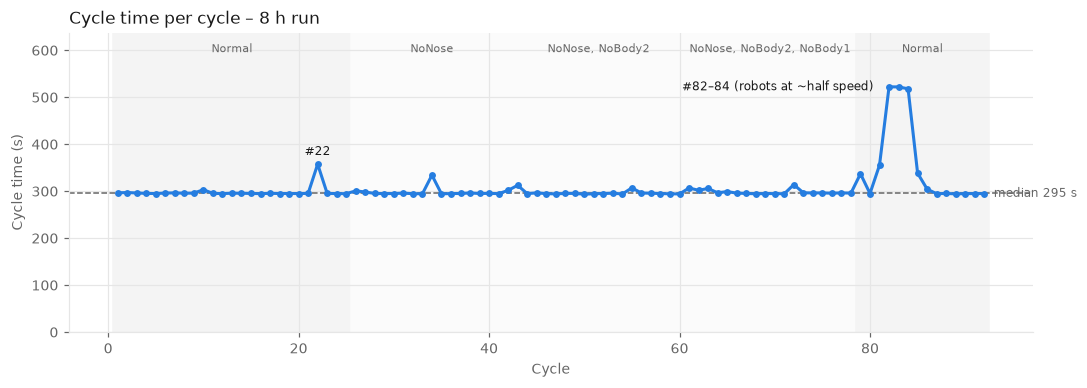

In [57]:
fig, ax = plt.subplots(figsize=(10, 3.6))
sc = cycles.loc[ct.index, 'scenario']
blocks = (sc != sc.shift()).cumsum()
for _, g in sc.groupby(blocks):
    shade = '#f4f4f4' if g.iloc[0] == 'Normal' else '#fbfbfb'
    ax.axvspan(g.index.min() - .5, g.index.max() + .5, color=shade, zorder=0)
    ax.text((g.index.min() + g.index.max()) / 2, ct.max() * 1.13, g.iloc[0], ha='center', va='bottom', fontsize=7.5, color=INK2)
ax.plot(ct.index, ct.values, color=COL['R01'], lw=2, marker='o', ms=3.5, zorder=3)
ax.axhline(med, color=INK2, lw=1, ls='--')
ax.text(ct.index.max() + 1, med, f'median {med:.0f} s', va='center', fontsize=8, color=INK2)
ax.annotate('#22', (22, ct[22]), textcoords='offset points', xytext=(0, 6), ha='center', fontsize=8, color=INK)
ax.annotate('#82–84 (robots at ~half speed)', (82, ct[82]), textcoords='offset points', xytext=(-10, 0), ha='right', va='center', fontsize=8, color=INK)
ax.set_xlabel('Cycle'); ax.set_ylabel('Cycle time (s)'); ax.set_ylim(0, ct.max() * 1.22)
ax.set_title('Cycle time per cycle – 8 h run', loc='left', color=INK, fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig1_cycle_time_run_chart.png')); plt.show()

Removing a part from the tray (defect scenarios) does **not** change the cycle time – the robots run the same program
whether a part is there or not. The variation comes from a few individual slow cycles, analysed in section 8.

## 7. Where does the time go? (typical cycle)

In [58]:
S = stt[[f'S{s:02d}' for s in STATES]]
normal = S.loc[ct[ct <= med * 1.05].index]           # 'undisturbed' cycles
summary = pd.DataFrame({'active': share['active'],
                        'median_s': normal.median(), 'mean_s': normal.mean(), 'std_s': normal.std(),
                        'min_s': normal.min(), 'max_s': normal.max()})
summary['cv_%'] = summary['std_s'] / summary['mean_s'] * 100
summary['share_%'] = summary['median_s'] / summary['median_s'].sum() * 100
summary.round(2)

,active,median_s,mean_s,std_s,min_s,max_s,cv_%,share_%
S01,R01,8.38,8.89,2.01,7.66,19.84,22.67,2.84
S02,R01,7.40,7.41,0.13,6.92,7.76,1.71,2.51
S03,R01,1.53,1.55,0.11,1.26,1.88,6.88,0.52
S04,R02,12.55,12.55,0.12,12.23,12.83,0.97,4.25
S05,R02,5.08,5.06,0.08,4.86,5.32,1.48,1.72
S06,R02,5.21,5.23,0.12,5.01,5.78,2.24,1.76
S07,R02,5.11,5.12,0.09,4.85,5.44,1.85,1.73
S08,R02 + R03,68.34,68.44,0.79,68.00,75.31,1.16,23.16
S09,No robot motion,85.51,85.81,1.36,84.55,96.03,1.58,28.98
S10,R04,11.05,11.07,0.23,10.70,12.98,2.10,3.74


In [59]:
by_robot = summary.groupby('active')['median_s'].sum().reindex(COL.keys())
print((by_robot / by_robot.sum() * 100).round(1).astype(str) + ' %')

active
R01                 5.9 %
R02                 9.5 %
R02 + R03          23.2 %
R04                32.5 %
No robot motion    29.0 %
Name: median_s, dtype: str


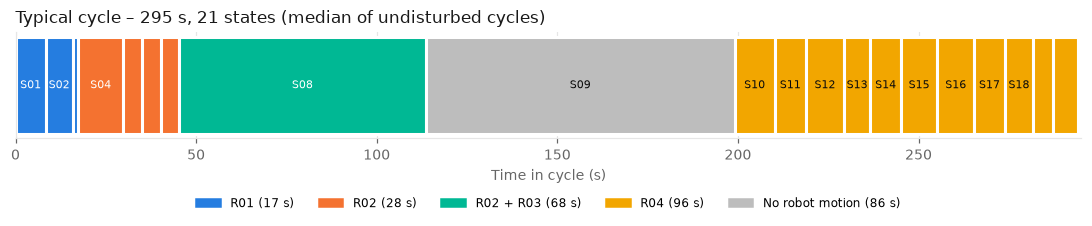

In [60]:
# Timeline of a typical cycle (median state times laid end to end)
fig, ax = plt.subplots(figsize=(10, 2.6))
t = 0
for s, r in summary.iterrows():
    ax.barh(0, r['median_s'], left=t, color=COL[r['active']], edgecolor='white', linewidth=2, height=0.55)
    if r['median_s'] > 7:
        ax.text(t + r['median_s'] / 2, 0, s, ha='center', va='center', fontsize=7.5,
                color='#0b0b0b' if r['active'] in ('R04', 'No robot motion') else 'white')
    t += r['median_s']
ax.set_yticks([]); ax.set_xlim(0, t); ax.set_xlabel('Time in cycle (s)'); ax.grid(axis='y', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, [f'{k} ({by_robot[k]:.0f} s)' for k in COL], ncol=5, loc='upper center', bbox_to_anchor=(.5, -.45),
          frameon=False, fontsize=8)
ax.set_title(f'Typical cycle – {t:.0f} s, 21 states (median of undisturbed cycles)', loc='left', color=INK, fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig2_typical_cycle_timeline.png'), bbox_inches='tight'); plt.show()

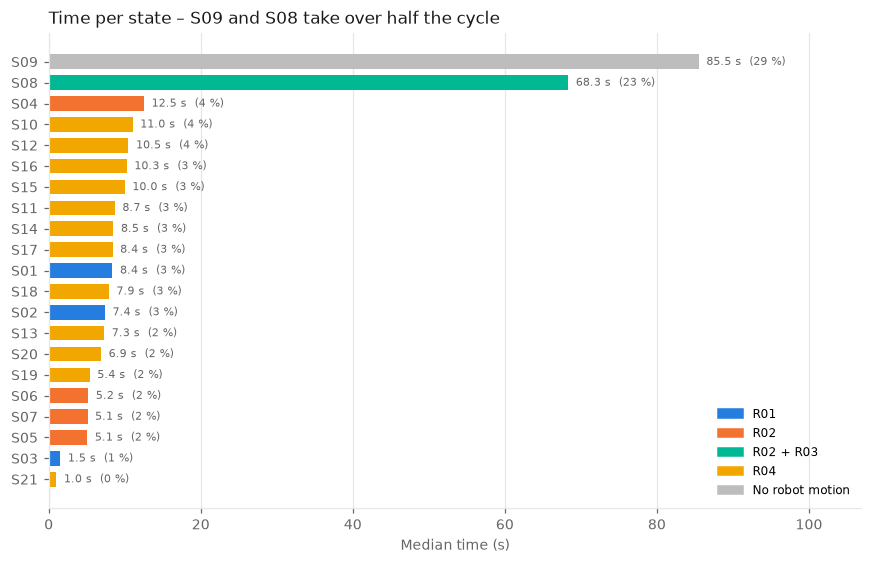

In [61]:
# Pareto of state times
p = summary.sort_values('median_s')
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(p.index, p['median_s'], color=[COL[a] for a in p['active']], height=0.7)
for i, (s, r) in enumerate(p.iterrows()):
    ax.text(r['median_s'] + 1, i, f"{r['median_s']:.1f} s  ({r['share_%']:.0f} %)", va='center', fontsize=7.5, color=INK2)
ax.set_xlabel('Median time (s)'); ax.grid(axis='y', visible=False); ax.set_xlim(0, p['median_s'].max() * 1.25)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()]
ax.legend(handles, COL.keys(), loc='lower right', frameon=False, fontsize=8)
ax.set_title('Time per state – S09 and S08 take over half the cycle', loc='left', color=INK, fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig3_state_pareto.png')); plt.show()

## 8. What happened in the slow cycles?
Extra time per state compared with the median of undisturbed cycles.

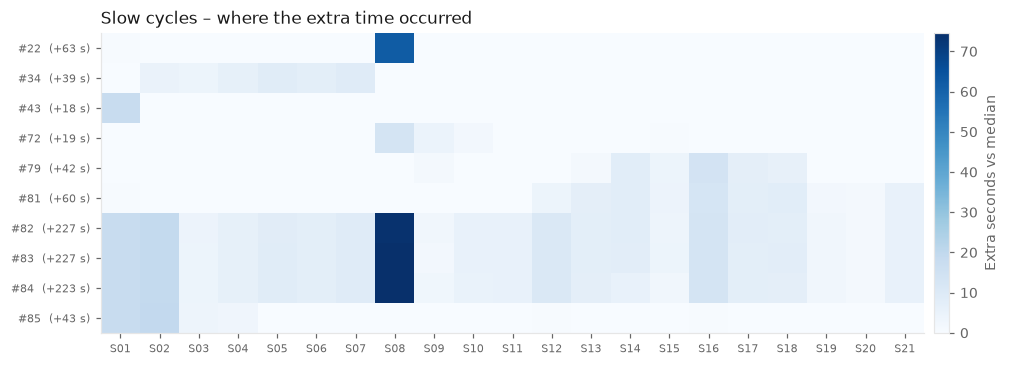

,S01,S02,S03,S04,S05,S06,S07,S08,S09,S10,...,S13,S14,S15,S16,S17,S18,S19,S20,S21,Total extra
cycle,,,,,,,,,,,,,,,,,,,,,
22,0.6,0.1,-0.2,0.1,-0.1,0.1,0.0,62.0,-0.1,0.1,...,-0.0,-0.0,0.0,-0.0,0.0,0.1,-0.0,-0.1,0.0,62.6
34,-0.1,4.9,4.0,6.3,8.7,7.3,8.8,-0.4,-0.3,0.0,...,0.0,0.1,0.0,-0.1,0.0,-0.0,0.1,-0.1,0.1,39.2
43,17.8,0.0,-0.0,0.1,-0.0,-0.0,0.0,0.2,-0.4,0.0,...,-0.0,0.1,0.0,0.0,-0.1,0.0,0.0,-0.0,0.0,17.6
72,-0.1,0.0,-0.0,0.1,0.0,-0.0,-0.0,13.4,4.6,1.8,...,-0.1,-0.0,0.3,-0.3,0.3,-0.3,0.0,0.1,-0.1,19.1
79,-0.1,-0.0,-0.0,0.3,-0.1,-0.2,-0.0,0.1,1.6,0.1,...,1.7,7.9,3.8,13.4,7.3,6.0,0.2,-0.0,0.1,42.1
81,0.4,-0.3,-0.0,0.1,-0.1,0.1,-0.0,-0.0,-0.5,0.0,...,7.2,8.1,4.2,12.8,7.5,7.9,2.0,1.7,5.6,60.5
82,17.9,19.0,4.3,6.3,8.3,7.5,9.0,74.0,2.6,5.4,...,7.3,8.1,3.8,13.2,7.6,7.4,2.5,1.5,5.7,227.2
83,17.8,19.1,4.1,6.2,8.6,7.4,8.8,74.6,2.0,5.4,...,7.4,7.8,3.8,13.2,7.5,7.6,2.4,1.5,5.7,227.1
84,17.9,19.0,4.1,6.3,8.5,7.4,8.8,74.3,2.6,5.2,...,7.2,5.3,2.5,13.4,7.6,7.2,2.4,1.6,5.6,223.1


In [62]:
extra = S.loc[slow.index].sub(summary['median_s'], axis=1)
extra['Total extra'] = extra.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(extra[S.columns].clip(lower=0).values, aspect='auto', cmap='Blues', vmin=0)
ax.set_xticks(range(21)); ax.set_xticklabels(S.columns, fontsize=7.5)
ax.set_yticks(range(len(extra))); ax.set_yticklabels([f'#{c}  (+{v:.0f} s)' for c, v in extra['Total extra'].items()], fontsize=7.5)
ax.grid(False)
cb = plt.colorbar(im, ax=ax, pad=0.01); cb.set_label('Extra seconds vs median', color=INK2)
ax.set_title('Slow cycles – where the extra time occurred', loc='left', color=INK, fontsize=11)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'fig4_slow_cycle_losses.png')); plt.show()
extra.round(1)

In [63]:
# Robot speed check: mean joint movement per sample while moving (deg / ~0.1 s)
def speed(c):
    x = motion[motion.cycle == c]
    return pd.Series({r: x.loc[x[r] > 0.05, r].mean() for r in ['R01','R02','R03','R04']})
spd = pd.DataFrame({f'#{c}': speed(c) for c in [int(ct[ct <= med*1.05].index[0])] + list(slow.index)}).T
spd.index.name = 'cycle (first row = normal reference)'
spd.round(2)

,R01,R02,R03,R04
cycle (first row = normal reference),,,,
#1,5.55,9.87,10.33,9.18
#22,5.54,5.99,5.19,9.08
#34,3.82,5.34,9.69,9.08
#43,2.79,9.89,10.43,9.14
#72,5.62,9.87,8.37,8.23
#79,5.51,9.82,10.35,6.53
#81,5.58,9.79,10.31,5.72
#82,1.76,3.89,4.53,4.90
#83,1.75,3.88,4.50,4.90


**Interpretation of the slow cycles**
- **#82–#84 (~+225 s each):** every robot state is slower and all four robots move at roughly half their normal
  joint speed → consistent with a **reduced robot speed setting** for ~26 min. The dataset does not record the reason.
- **#22 (+63 s):** almost all of it in **S08 (assembly)**, with R02/R03 moving at about half speed.
- **#34, #43, #85:** R01 and/or R02 states slower (lower R01/R02 joint speed).
- **#79, #81:** R04 (disassembly) states slower.
- **#72 (+19 s):** extra time in S08 and S09.

In every slow cycle the extra time comes with lower joint speed of the robot(s) involved – the cell slowed down, it did not stop.

The R02 gripper potentiometer failure at 18:19 (cycle 53) did **not** affect cycle time – that is a sensor fault,
picked up in Phase 3 (anomaly detection).

## 9. Export

In [64]:
xlsx = os.path.join(OUT_DIR, 'phase1_state_time_table.xlsx')
with pd.ExcelWriter(xlsx) as w:
    out = stt.copy(); out.insert(0, 'scenario', cycles.loc[stt.index, 'scenario']); out.insert(0, 'start_utc', cycles.loc[stt.index, 'start'].dt.tz_localize(None))
    out.round({c: 2 for c in stt.columns}).to_excel(w, sheet_name='state_times')
    summary.round(2).to_excel(w, sheet_name='state_summary')
    share.round(3).to_excel(w, sheet_name='robot_per_state')
    extra.round(2).to_excel(w, sheet_name='slow_cycles_extra')
print('Saved to', OUT_DIR)

Saved to E:\claude github projects\future-factories\outputs


## 10. Key findings (Phase 1)
*(numbers are filled from the outputs above – re-check if you re-run on other data)*

1. **92 complete cycles** in 8 h; median cycle time **≈ 295 s**, very stable (72 of 92 cycles within ±1 % of the median).
2. **S09 (≈ 85 s, ~29 %)** has no robot motion – the tray is on the conveyor / waiting. **S08 assembly (≈ 68 s, ~23 %)** is the longest robot state.
   Together they are over half of every cycle → the first targets for improvement.
3. The cell runs **strictly sequentially** – only one robot moves at a time. R04 (disassembly, S10–S21) alone takes ~33 % of the cycle.
4. Missing parts in the tray (defect scenarios) do **not** change cycle time.
5. **~16 min (≈ 3 cycles of output) was lost** in 10 slow cycles (>5 % above median); ~70 % of that comes from cycles #82–#84,
   where all robots ran at about half speed.

**Next – Phase 2:** control charts (I-MR) of cycle time and S08/S09, and capability against a target cycle time.